# 2025-03-03: Data Distribution of CHILDES

## Prelude

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from verb_overgen.prep.common import Parse

In [3]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from os import environ

In [4]:
dataset = pl.read_parquet(f"{environ['DATA_PATH_BASE']}/babylm/20250305T043455.aochildes_parsed.parquet")

In [8]:
from functools import partial
from verb_overgen.prep.lib.pattern_matching import match_svo
from verb_overgen.prep.lib.lexical import to_lemma

dataset_trans_verb = dataset.filter(
    pl.col("parse").is_not_null(),
    pl.col("parse").struct.field("rel").pipe(lambda r: r.list.contains("nsubj") & r.list.contains("dobj"))
).with_columns(
    trans_verb_index := pl.col("parse").pipe(match_svo).alias("trans_verb_index"),
    trans_verb := pl.col("parse").struct.field("word").list.gather(trans_verb_index - 1).alias("trans_verb"),
    trans_verb_lemma := trans_verb.list.eval(pl.element().map_elements(partial(to_lemma, pos="v"), return_dtype=pl.String)).alias("trans_verb_lemma")
)

This is the Roberta version.

Take the word "talk" as an example, which is clearly not a transitive verb. Dangling prepositions can break the parser.

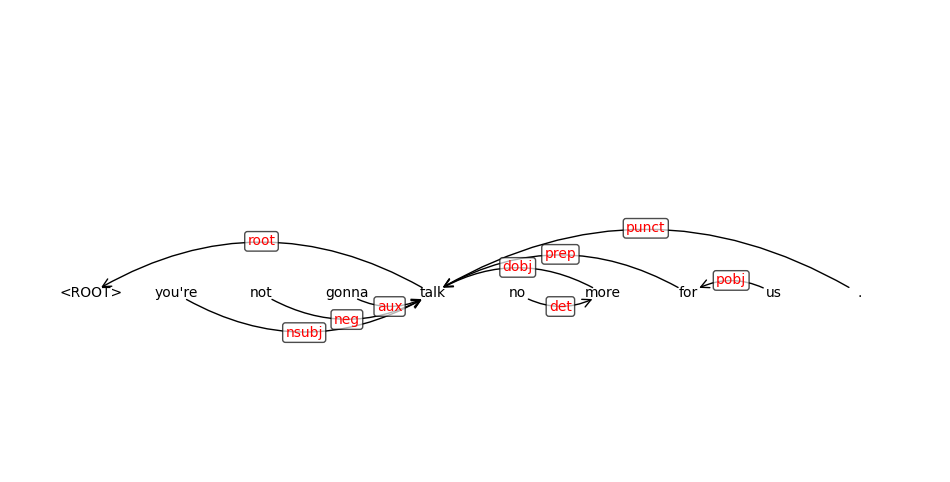

In [13]:
from verb_overgen.prep.lib.graph import create_parse_graph, draw_parse_graph

dataset_transitive_talk = dataset_trans_verb.filter(
    pl.col("trans_verb_lemma").list.contains("talk")
)

draw_parse_graph(create_parse_graph(dataset_transitive_talk[3, "parse"])).show()

Malformed sentences still form parse errors.

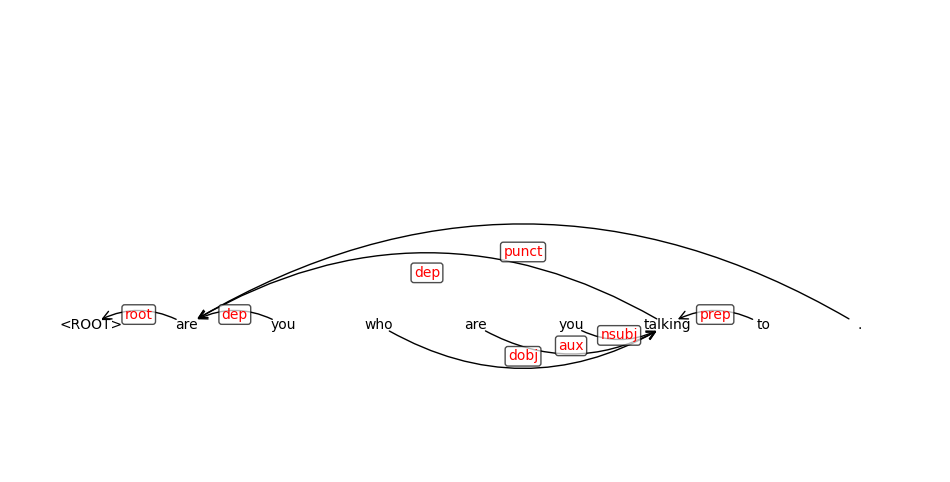

In [14]:
draw_parse_graph(create_parse_graph(dataset_transitive_talk[4, "parse"])).show()

# Bidgood (2021) Verbs

We now pull over Bidgood's (2021) verb sheet and check the distribution of verb categories in the parsed sentences.

In [15]:
from verb_overgen.prep.lib.lexical import BIDGOOD_VERBS

df_bidgood_v = pl.DataFrame([(category, word) for category, s in BIDGOOD_VERBS.items() for word in s], orient="row", schema=pl.Schema({
    "category": pl.Enum(BIDGOOD_VERBS.keys()),
    "word": pl.String
}))

In [16]:
df_trans_verb_count = dataset_trans_verb.select(
    pl.col("trans_verb_lemma").list.explode().value_counts().struct.rename_fields(["word", "count"]).struct.unnest()
)

df_bidgood_v_count = df_bidgood_v.join(df_trans_verb_count, on="word", how="left", maintain_order="left").with_columns(
    pl.col("count").fill_null(0)
)

In [17]:
df_bidgood_v_count.group_by("category").agg(pl.sum("count"))

category,count
enum,u32
"""intransitive_only""",1781
"""transitive_only""",4007
"""alternating""",1473


Far less intransitive verbs are calculated as transitive verbs.

In [18]:
with pl.Config(set_tbl_rows=-1):
    display(df_bidgood_v_count.filter(pl.col("category") == "intransitive_only").sort("count", descending=True))

category,word,count
enum,str,u32
"""intransitive_only""","""eat""",957
"""intransitive_only""","""go""",419
"""intransitive_only""","""drink""",151
"""intransitive_only""","""sing""",127
"""intransitive_only""","""talk""",33
"""intransitive_only""","""climb""",23
"""intransitive_only""","""run""",19
"""intransitive_only""","""come""",16
"""intransitive_only""","""jump""",10


Let's first check the example "laugh":